# YOLO-World on soybean insects

Run this notebook from the repository root with the CS117 kernel. Run through **Score** for the stock baseline, then run **Fine-tune** for a training experiment. To try another prompt or confidence cutoff, edit **Settings**, run that cell, then rerun **Preview** or **Score**. Use validation while experimenting and test for the final comparison.

In [52]:
from pathlib import Path

import matplotlib.pyplot as plt
import torch
import yaml
from IPython.display import clear_output
from ultralytics import YOLOWorld

data_dir = Path("data/INSECT12C").resolve()
split_files = {name: f"{name}_images.txt" for name in ("train", "val", "test")}
work_dir = Path("runs/insect_experiments").resolve()

weights = "models/yolov8s-worldv2.pt"
best = Path("runs/insect_experiments/finetune/weights/best.pt")  # saved three-epoch run
model = YOLOWorld(weights)
model = model.to("cuda" if torch.cuda.is_available() else "cpu")

## Settings

In [53]:
prompt = "insect"
split = "val"  # "val" or "test"

settings = {
    "conf": 0.001,  # minimum confidence to keep a box
    "imgsz": 640,   # input image size
    "iou": 0.45,    # NMS overlap threshold for removing duplicate boxes
}

model.set_classes([prompt])

# Ultralytics reads the class name and split paths from a YAML file.
work_dir.mkdir(parents=True, exist_ok=True)
dataset_yaml = work_dir / "dataset.yaml"
with dataset_yaml.open("w", encoding="utf-8") as file:
    yaml.safe_dump({"path": str(data_dir), **split_files, "names": [prompt]}, file)

## Dataset splits

The notebook reads the local images, labels, and split lists in [data/INSECT12C](data/INSECT12C/README.md). Following [Joshua's split](scripts/finetune.py), parts 02 through 11 are training and part 12 is validation. Test uses part 01 with the ten smoke-test photos excluded.

In [54]:
splits = {}
for name, filename in split_files.items():
    lines = (data_dir / filename).read_text(encoding="utf-8").splitlines()
    splits[name] = [data_dir / line for line in lines]
    print(f"{name}: {len(lines)} images")

train: 1500 images
val: 150 images
test: 140 images


## Preview

Predictions on the ten photos from the original smoke test.

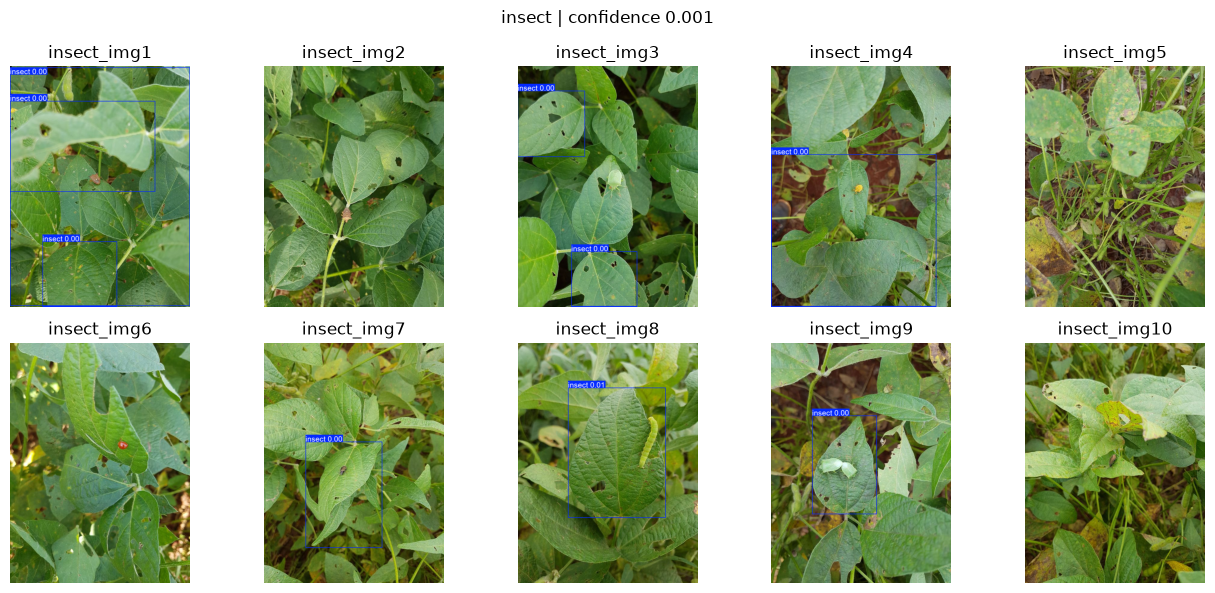

In [55]:
photos = [Path(f"data/smoke_images/insect_img{i}.jpg") for i in range(1, 11)]
predictions = model.predict(photos, **settings, verbose=False)

fig, axes = plt.subplots(2, 5, figsize=(13, 6))
for ax, photo, prediction in zip(axes.flat, photos, predictions):
    ax.imshow(prediction.plot(pil=True))
    ax.set_title(photo.stem)
    ax.axis("off")
fig.suptitle(f"{prompt} | confidence {settings['conf']}")
fig.tight_layout()
plt.show()

## Score

Every labeled species counts as an insect. A prediction needs at least 50% box overlap (IoU) to count as a match. Precision and recall below use the confidence you set above. The stock baseline uses [Xavier's YOLO-World setup](https://github.com/EPatrick7/CS-117-Insect-Detection/blob/4906473/scripts/baseline.py).

In [56]:
def score(detector):
    metrics = detector.val(
        data=str(dataset_yaml), split=split, single_cls=True, **settings,
        batch=8, workers=0, plots=False, verbose=False,
        project=str(work_dir), name=split, exist_ok=True,
    )
    images = metrics.box.image_metrics.values()
    tp = sum(image["tp"] for image in images)
    fp = sum(image["fp"] for image in images)
    fn = sum(image["fn"] for image in images)
    return dict(images=len(images), matches=tp, false_alarms=fp, misses=fn,
                precision=tp / max(tp + fp, 1), recall=tp / max(tp + fn, 1),
                mAP50=float(metrics.box.map50), mAP50_95=float(metrics.box.map))


stock = score(model)
clear_output(wait=True)
print(f"{prompt!r} on {stock['images']} {split} images (conf={settings['conf']})")
print(f"Matches: {stock['matches']}   False alarms: {stock['false_alarms']}   Missed insects: {stock['misses']}")
print(f"Precision {stock['precision']:.2%}   Recall {stock['recall']:.2%}")
print(f"mAP@0.50 {stock['mAP50']:.4f}   mAP@0.50:0.95 {stock['mAP50_95']:.4f}")

'insect' on 150 val images (conf=0.001)
Matches: 3   False alarms: 86   Missed insects: 210
Precision 3.37%   Recall 1.41%
mAP@0.50 0.0031   mAP@0.50:0.95 0.0011


## Fine-tune

This starts a new run from the stock weights. Each epoch uses all 1,500 training images. Validation selects the best checkpoint. Change the epoch count or batch size here. Training is adapted from [Joshua's fine-tuning script](https://github.com/EPatrick7/CS-117-Insect-Detection/blob/ae8186d/scripts/finetune.py). The notebook keeps the selected prompt when Ultralytics combines the species into one class.

In [57]:
from ultralytics.models.yolo.world import WorldTrainer

epochs = 3
batch = 4


class InsectTrainer(WorldTrainer):
    def get_dataset(self):
        data = super().get_dataset()
        data["names"] = {0: prompt}  # single_cls otherwise renames the class to "item"
        return data


training_model = YOLOWorld(weights)
training_model.train(
    trainer=InsectTrainer, data=str(dataset_yaml), single_cls=True, epochs=epochs, batch=batch,
    imgsz=settings["imgsz"], workers=0, plots=False, patience=10, save_period=5, seed=0,
    project=str(work_dir), name="finetune",
)
best = Path(training_model.trainer.best)
del training_model
clear_output(wait=True)
print(f"Best checkpoint: {best}")

Best checkpoint: C:\Users\thepi\Documents\GitHub\CS-117-Insect-Detection\runs\insect_experiments\finetune-6\weights\best.pt


## Compare stock and fine-tuned

Both models use the current prompt, split and detection settings. To compare on test after training, change `split` to `"test"` in **Settings**, run that cell, then rerun the cell below. You can also set `best` to an existing checkpoint path to skip training.

In [58]:
import json

tuned = YOLOWorld(str(best))
comparison = {"stock": score(model), "fine_tuned": score(tuned)}
clear_output(wait=True)
print(f"{prompt!r} on {len(splits[split])} {split} images (conf={settings['conf']})")
print("Model        Matches  False alarms  Misses  Precision   Recall    mAP50  mAP50-95")
for name, row in comparison.items():
    print(f"{name:11} {row['matches']:7} {row['false_alarms']:13} {row['misses']:7} "
          f"{row['precision']:9.2%} {row['recall']:8.2%} {row['mAP50']:8.4f} {row['mAP50_95']:9.4f}")

run = Path(best).parent.parent.name
#output = Path("results") / f"{run}_{split}.json"
#output.parent.mkdir(exist_ok=True)
#output.write_text(json.dumps({"checkpoint": Path(best).as_posix(), "prompt": prompt, "split": split,"settings": settings, "scores": comparison}, indent=2) + "\n")
#print(f"Saved {output}")

'insect' on 150 val images (conf=0.001)
Model        Matches  False alarms  Misses  Precision   Recall    mAP50  mAP50-95
stock             3            86     210     3.37%    1.41%   0.0031    0.0011
fine_tuned      208          5043       5     3.96%   97.65%   0.8188    0.4016


## Which insects did each model find?

Each column shows one photo. The stock model is on top and the fine-tuned model is below. Dashed cyan boxes show where a person marked an insect. Every solid orange box is a model prediction.

A guess counts as a find when it overlaps a human box closely enough (IoU of at least 0.50). Each marked insect counts once. The caption gives the number found and the number of extra guesses.

Change the photos or cutoff in the prediction cell. The helper cell uses [Joshua's label reader and matcher](scripts/error_analysis.py) to annotate one photo. Change colors or layout in the final cell and rerun it using the existing predictions. From a fresh kernel, run setup, Settings and Dataset splits first.

In [59]:
gallery_split = "val"
gallery_photos = splits[gallery_split][::50]  # first photo and then every 50th
gallery_conf = 0.25

gallery_models = {"Stock": model, "Fine-tuned": YOLOWorld(str(best))}
gallery_results = {}
for name, detector in gallery_models.items():
    if list(detector.names.values()) != [prompt]:
        detector.set_classes([prompt])
    gallery_results[name] = detector.predict(
        gallery_photos, conf=gallery_conf, imgsz=settings["imgsz"], iou=settings["iou"], verbose=False
    )

In [60]:
import numpy as np
from matplotlib.patches import Rectangle

from scripts.error_analysis import match, read_boxes


def draw_boxes(ax, boxes_xywh, image_shape, *, color, linestyle="-"):
    """Draw boxes given as normalized center x, center y, width, and height."""
    height, width = image_shape
    pixel_boxes = boxes_xywh * [width, height, width, height]

    for center_x, center_y, box_width, box_height in pixel_boxes:
        top_left = (center_x - box_width / 2, center_y - box_height / 2)
        rectangle = Rectangle(
            top_left, box_width, box_height, fill=False,
            edgecolor=color, linestyle=linestyle, linewidth=1.6,
        )
        ax.add_patch(rectangle)


def plot_detection(ax, model_name, result, labels, *, prediction_color, label_color):
    boxes = result.boxes.cpu()
    predicted_xywh = boxes.xywhn.numpy()
    # Joshua's matcher expects [class, center x, center y, width, height, confidence].
    predictions = np.column_stack((boxes.cls.numpy(), predicted_xywh, boxes.conf.numpy()))
    matched, *_ = match(labels, predictions, iou_thr=0.5, match_class=False)
    found = int(matched.sum())

    ax.imshow(result.orig_img[:, :, ::-1])  # Ultralytics stores images in BGR order.
    draw_boxes(ax, predicted_xywh, result.orig_shape, color=prediction_color)
    draw_boxes(ax, labels[:, 1:5], result.orig_shape, color=label_color, linestyle="--")
    ax.axis("off")

    insect = "insect" if len(labels) == 1 else "insects"
    title = f"{model_name} found {found} of {len(labels)} {insect}"
    counts = f"Model guesses: {len(boxes)}   |   Extra: {len(boxes) - found}"
    ax.set_title(f"{title}\n{counts}", loc="left", fontsize=11)

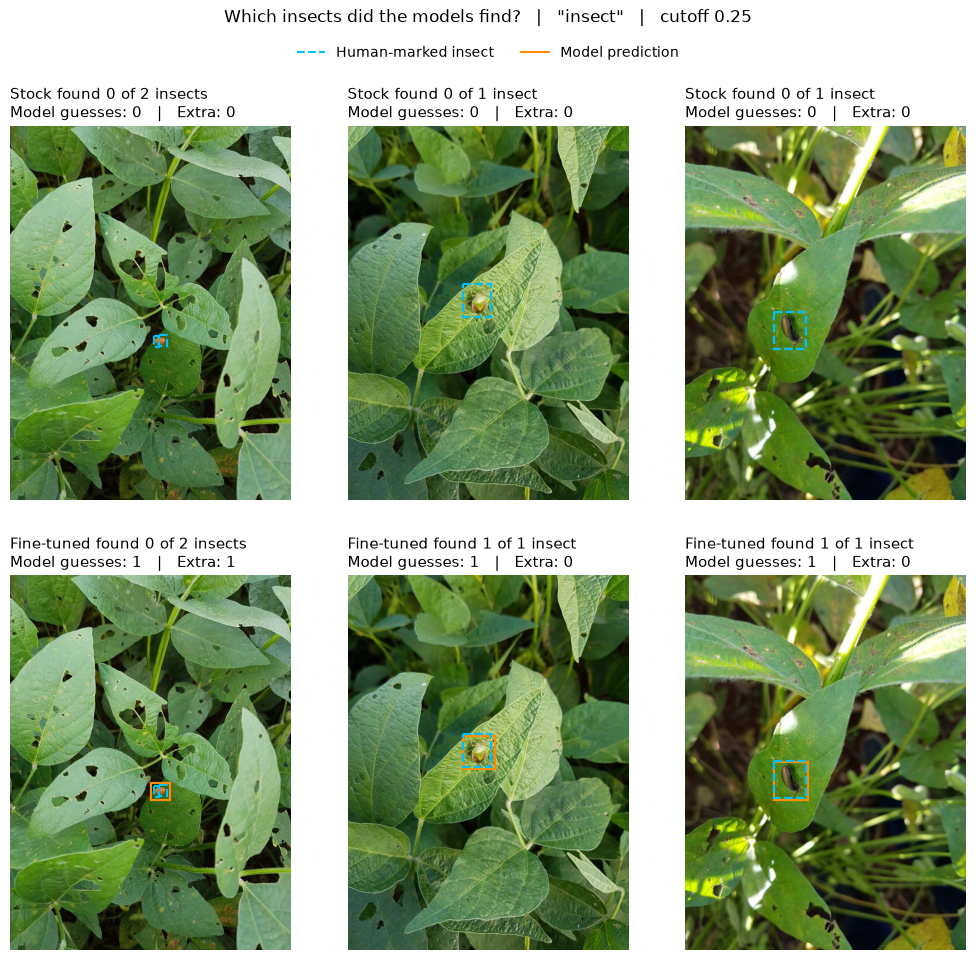

In [61]:
from matplotlib.lines import Line2D

prediction_color = "darkorange"
label_color = "deepskyblue"

columns = len(gallery_photos)
fig, axes = plt.subplots(
    len(gallery_results), columns, squeeze=False, figsize=(max(5, 3.4 * columns), 9.7),
)

for col, photo in enumerate(gallery_photos):
    labels = read_boxes(photo.with_suffix(".txt"), with_conf=False)
    for row, (model_name, results) in enumerate(gallery_results.items()):
        plot_detection(
            axes[row, col], model_name, results[col], labels,
            prediction_color=prediction_color, label_color=label_color,
        )

fig.suptitle(f'Which insects did the models find?   |   "{prompt}"   |   cutoff {gallery_conf:g}')
legend = [
    Line2D([], [], color=label_color, linestyle="--", label="Human-marked insect"),
    Line2D([], [], color=prediction_color, label="Model prediction"),
]
fig.legend(handles=legend, loc="upper center", bbox_to_anchor=(0.5, 0.955), ncol=2, frameon=False)
fig.subplots_adjust(left=0.01, right=0.99, bottom=0.01, top=0.86, wspace=0.04, hspace=0.20)

# output = Path("results") / f"stock_vs_{Path(best).parents[1].name}_{gallery_split}_conf_{gallery_conf:g}.jpg"
# output.parent.mkdir(exist_ok=True)
# fig.savefig(output, dpi=160, bbox_inches="tight", pil_kwargs={"quality": 94})
plt.show()